# Reproducing "Scalable and Generalizable Social Bot Detection through Data Selection"
*Yang, Varol, Hui & Menczer (AAAI 2020)*

## The problem
**Social bots** are automated accounts that pose as real people on social media, often to spread spam or misinformation.
Researchers train machine-learning models to spot them, and these models usually score almost perfectly when tested on
the same dataset they were trained on. On accounts from a **different** dataset, though, they often perform much worse,
because bots keep changing and every dataset is collected differently. A detector that only works on its own data is
of little use in practice.

## What the paper proposes
1. **A simple, fast detector:** a random forest that uses only **20 features** from an account's public profile
   (follower counts, how fast it tweets, how random its username looks, ...). No tweets are needed, so it can check
   millions of accounts.
2. **Data selection:** instead of training on all available data, try many **combinations** of training datasets and
   keep the one that performs best on data it was **not** trained on. The paper finds that a well-chosen subset
   generalizes better than using everything.

## What we did
The paper's datasets are no longer available, so we used the two we could get: **cresci-17** (about 14,000 accounts
from 2014–2015, with 8 types of bots) for training, and **TwiBot-22** (about 1 million accounts from 2022) as unseen
test data.

| Step | Question | Result (AUC*) |
|---|---|---|
| 1. Build the paper's 20 features | | |
| 2. 5-fold cross-validation on cresci-17 | Does it work on the data it learned from? | 0.998 |
| 3. Leave one bot type out | Can it catch a bot type it never saw? | 0.969–0.998 |
| 4. Train on cresci-17, test on TwiBot-22 | Does it work on a new dataset? | **0.606** |
| 5. Data selection over the 8 bot types | Does choosing the training data help? | **0.649** |

In [1]:
# to RUN
# 1. create virtual environment in terminal
#   python3 -m venv .venv  
#   source .venv/bin/activate
# 2. select kernel (top right) -> python -> virtual environement
# 3. run cells

In [1]:
%pip install pandas 
%pip install numpy 
%pip install scikit-learn 
%pip install matplotlib
%pip install ijson

  Using cached pandas-3.1.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (16 kB)
  Using cached numpy-2.5.5-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
Using cached pandas-3.1.1-cp314-cp314-macosx_11_0_arm64.whl (11.3 MB)
Using cached numpy-2.5.5-cp314-cp314-macosx_14_0_arm64.whl (5.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]2m1/2 [pandas]

[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.met

In [2]:
from collections import defaultdict
from itertools import combinations
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, precision_recall_fscore_support, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
import ijson
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


## Data Processing

In [3]:
location = 'data/cresci-17/datasets_full.csv/datasets_full.csv/'
dfs = {
    "genuine": pd.read_csv(f'{location}genuine_accounts.csv/users.csv'),
    "fake_followers": pd.read_csv(f'{location}fake_followers.csv/users.csv'),
    "spam_bot_1": pd.read_csv(f'{location}social_spambots_1.csv/users.csv'),
    "spam_bot_2": pd.read_csv(f'{location}social_spambots_2.csv/users.csv'),
    "spam_bot_3": pd.read_csv(f'{location}social_spambots_3.csv/users.csv'),
    "trad_spam_bot_1": pd.read_csv(f'{location}traditional_spambots_1.csv/users.csv'),
    "trad_spam_bot_2": pd.read_csv(f'{location}traditional_spambots_2.csv/users.csv'),
    "trad_spam_bot_3": pd.read_csv(f'{location}traditional_spambots_3.csv/users.csv'),
    "trad_spam_bot_4": pd.read_csv(f'{location}traditional_spambots_4.csv/users.csv')
}

In [4]:
# 1 = bot, 0 = human
for name, df in dfs.items():
    if name == "genuine":
        df["is_bot"] = 0
    else:
        df["is_bot"] = 1
    df["from_dataset"] = name


In [5]:
# ignore_index=True resets indices back to 0..n
combined = pd.concat(dfs.values(), ignore_index=True)

In [6]:
# fix NaNs
nan_cols = combined.columns[combined.isna().any()].tolist()

# default values for columns used in the paper
col_defaults = {
    "default_profile": 0,
    "verified": 0,
    "profile_use_background_image": 0, 
    "description": "",
    "name": ""
}

# fill to default values
for col in nan_cols:
    if col in col_defaults:
        combined[col] = combined[col].fillna(col_defaults[col])

# check, should be an empty df
combined[combined["default_profile"] == "NULL"]  
combined[combined["default_profile"].isna()]
combined[combined["profile_use_background_image"].isna()]
combined[combined["profile_use_background_image"] == "NULL"]

,id,name,screen_name,statuses_count,followers_count,friends_count,favourites_count,listed_count,url,lang,...,contributors_enabled,following,created_at,timestamp,crawled_at,updated,test_set_1,test_set_2,is_bot,from_dataset


In [7]:
# paper uses probe time as the moment the user object was retrieved, we
# use cresci-17’s crawled_at field (and updated for fake_followers, which doesn't heave a crawled_at col).
updated_col = combined[combined["from_dataset"] == "fake_followers"]["updated"]
combined.loc[combined["from_dataset"] == "fake_followers", "crawled_at"] = updated_col

In [8]:
# make times match
def convert_date(date):
    date = str(date).strip()

    # nnix timestamp in milliseconds
    if date.endswith("L") or date.isdigit():
        return pd.to_datetime(int(date.rstrip("L")), unit="ms", utc=True)

    # automatically infer other date formats
    return pd.to_datetime(date, format="mixed", utc=True)


combined["created_at"] = combined["created_at"].apply(convert_date)
combined["crawled_at"] = combined["crawled_at"].apply(convert_date)

## Feature Table

**User Metadata:**
These come straight from the data

| # | Feature | Column Name |
|---|---|---|
| 1 | Statuses Count | `statuses_count` |
| 2 | Followers Count | `followers_count` |
| 3 | Friends Count | `friends_count` |
| 4 | Favourites Count | `favourites_count` |
| 5 | Listed Count | `listed_count` |
| 6 | Default Profile | `default_profile` |
| 7 | Profile Use Background Image | `profile_use_background_image` |
| 8 | Verified | `verified` |

In [9]:
# feature definitions, used by build_features() below
RAW_FEATURES = [  # copied straight from the data
    "statuses_count",
    "followers_count",
    "friends_count",
    "favourites_count",
    "listed_count",
    "default_profile",
    "profile_use_background_image",
    "verified",
]

RATE_FEATURES = [  # [name, numerator] -> numerator / age
    ["tweet_freq", "statuses_count"],
    ["followers_growth_rate", "followers_count"],
    ["friends_growth_rate", "friends_count"],
    ["favourites_growth_rate", "favourites_count"],
    ["listed_growth_rate", "listed_count"],
]

STRING_FEATURES = [  # [name, column, operation]
    ["screen_name_length", "screen_name", "length"],
    ["num_digits_in_screen_name", "screen_name", "digits"],
    ["name_length", "name", "length"],
    ["num_digits_in_name", "name", "digits"],
    ["description_length", "description", "length"],
]


**Derived Features:** These were derived using some formula

| # | Feature | Formula |
|---|---|---|
| 9 | `tweet_freq` | `statuses_count / age` |
| 10 | `followers_growth_rate` | `followers_count / age` |
| 11 | `friends_growth_rate` | `friends_count / age` |
| 12 | `favourites_growth_rate` | `favourites_count / age` |
| 13 | `listed_growth_rate` | `listed_count / age` |
| 14 | `followers_friends_ratio` | `followers_count / max(friends_count, 1)` |
| 15 | `screen_name_length` | Number of characters in `screen_name` |
| 16 | `num_digits_in_screen_name` | Number of numeric characters (0–9) in `screen_name` |
| 17 | `name_length` | Number of characters in `name` |
| 18 | `num_digits_in_name` | Number of numeric characters (0–9) in `name` |
| 19 | `description_length` | Number of characters in `description` |
| 20 | `screen_name_likelihood` | likelihood of the `screen_name` |

In [10]:
# helpers
def get_age(df, probe=None):
    if probe is None:
        ages = (df["crawled_at"] - df["created_at"]).dt.total_seconds() / 3600
    else:
        ages = (probe - df["created_at"]).dt.total_seconds() / 3600
    # floor at 1 hour to avoid dividing by 0
    return ages.clip(lower=1)

# refactored to not have to build features every time 
def build_features(df, probe=None):
    table = pd.DataFrame(index=df.index)  # same row labels as df, so it lines up with y
    age = get_age(df, probe)

    # 1-8: raw features (astype(float) also turns True/False into 1.0/0.0)
    for col in RAW_FEATURES:
        if col in df.columns:
            table[col] = df[col].astype(float)

    # 9-13: rate features
    for name, numerator in RATE_FEATURES:
        if numerator in df.columns:
            table[name] = df[numerator] / age

    # 14: followers / max(friends, 1)
    table["followers_friends_ratio"] = df["followers_count"] / df["friends_count"].clip(lower=1)

    # 15-19: string features
    for name, col, operation in STRING_FEATURES:
        text = df[col].fillna("").astype(str)
        if operation == "length":
            table[name] = text.str.len()
        else:
            table[name] = text.str.count(r"\d")

    # 20: screen-name likelihood
    table["screen_name_likelihood"] = df["screen_name"].fillna("").astype(str).apply(get_username_score)

    return table


### Feature: Screen-Name Likelihood
> For this part, we are looking to assign values that give a username a score on how likely it is to be a humna or bot user based on the user name

The paper does this by assiging bigrams ("jehu_z" -> "je", "eh", "hu", "u_", and "_z") scores and combining them for a username. 
The idea here is that normal usernames use common bigrams like "an" or "ch" and bot accounts use more random ones like "rx", or "qz". 

Paper says "We collected over 2M unique screen names and constructed the likelihood of all 3,969 possible bigrams."  Twibot-22 dataset is used here since thats what we have available.

1. read user names from twibot-22 dataset user.json
2. count bigrams of each username and track the total

In [11]:
# json is very large, use ijson to stream

bigram_freq = defaultdict(int)
valid = set("abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_")

# only count names that use the charcters in valid
def is_valid(bi):
    for ch in bi:
        if ch not in valid:
            return False
    return True

# same user not counted again (a user can appear more than once)
seen = set()

with open("data/twibot-22/user.json", "rb") as file:
    for user in ijson.items(file, "item"):
        username = user.get("username") or ""
        if username not in seen:
            for i in range(len(username) - 1):
                bigram = username[i:i+2]
                if is_valid(bigram):
                    bigram_freq[bigram] += 1
            seen.add(username)


In [12]:
total = sum(bigram_freq.values())
# gets the P(bigram)
def P_bi(bigram):
    # accounts for any bigram that does not appear, add 1 to all counts / by since we added 1 3669 times (since we counted extras)
    return (bigram_freq.get(bigram, 0) + 1) / (total + len(valid) ** 2)

# sanity check
total_P = 0
possible = "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_"
for i in range(len(possible)):
    for j in range(len(possible)):
        bigram = possible[i] + possible[j]
        total_P += P_bi(bigram)

print(total_P) # should be 0.999999.. or 1.0000..

# we split user names into bigrams
# take geometric mean like paper does -> p1, p2, ..., pn  =  (p1 × p2 × ... × pn) ^ (1/n)
# take log to avoid overflow since log(a × b × c) / n = (log a + log b + log c) / n
# Then you undo the log with exp to get back to a probability
def get_username_score(username):
    if len(username) < 2:
        return 0

    log_sum = 0
    total_bis = 0
    for i in range(len(username)-1):
        bigram = username[i:i+2]
        if is_valid(bigram):
            P = P_bi(bigram)
            total_bis += 1
            log_sum += np.log(P)
    
    if total_bis == 0:
        return 0

    log_mean = log_sum / total_bis
    return np.exp(log_mean)


0.999999999999999


In [13]:
X = build_features(combined)
y = combined["is_bot"]
X.shape


(14368, 20)

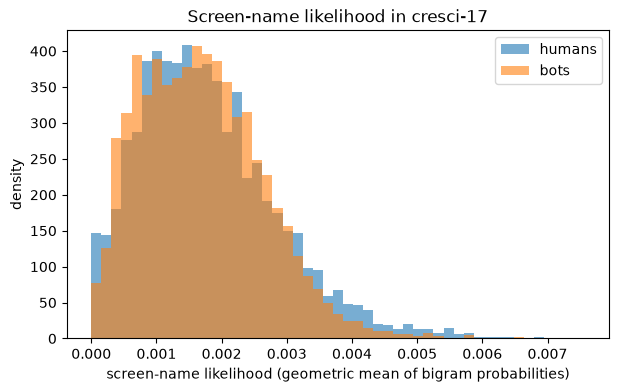

is_bot
humans    0.001789
bots      0.001701
Name: screen_name_likelihood, dtype: float64


In [14]:
# does the screen-name likelihood separate humans from bots?
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, X["screen_name_likelihood"].max(), 50)
ax.hist(X.loc[y == 0, "screen_name_likelihood"], bins=bins, alpha=0.6, density=True, label="humans")
ax.hist(X.loc[y == 1, "screen_name_likelihood"], bins=bins, alpha=0.6, density=True, label="bots")
ax.set_xlabel("screen-name likelihood (geometric mean of bigram probabilities)")
ax.set_ylabel("density")
ax.set_title("Screen-name likelihood in cresci-17")
ax.legend()
plt.show()

print(X.groupby(y)["screen_name_likelihood"].mean().rename({0: "humans", 1: "bots"}))

- **x-axis:** each account’s screen-name likelihood. Higher means the username is made of common letter pairs, like real names. Lower means it looks more random.
- **y-axis:** density, meaning how common each score is within each group. It’s scaled so humans and bots can be compared even though there are 3× more bots.

The screen-name likelihood distributions of humans and bots almost completely overlap (mean 0.00179 vs. 0.00170), so the feature adds little on cresci-17, whose bots mostly have human-like usernames rather than random strings.

## Building the Classifier

### 5-Fold Cross-Validation

> Can the model recognize new accounts of a type it already knows?

The data is split at random into 5 subsets (folds) containing the same ratio of bot types (social spambots, traditional spambots, and fake followers) along with genuine accounts. The model then trains on 4 of folds and test on a the 5th, rotating until each fold has been tested once. 

Round 1:  [TEST] [train] [train] [train] [train] <br>
Round 2:  [train] [TEST] [train] [train] [train] <br>
Round 3:  [train] [train] [TEST] [train] [train] <br>
Round 4:  [train] [train] [train] [TEST] [train] <br>
Round 5:  [train] [train] [train] [train] [TEST] <br>

Since every type of bot appears in both training and testing, the model is only ever tested on kinds of bots it has already seen, just not the exact same accounts.

In [15]:
# paramters:
# n_estimators: the number of trees in the forest.
# criterion: function to measure quality of split (default is already Gini)
# min_samples_split: minimum number of samples required to split an internal node
# min_samples_leaf: the minimum number of samples required to be at a leaf node.
# max_depth: max depth of tree (default is None, will go until leaves are pure or hit less than min_samples_split)
# random_state: seed for random (makes random choices same every time)
# n_jobs: number of jobs to run in parrallel (None means 1, -1 means all)
# ... a bunch more https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# spkit data into train/test sets
# n_splits: number of folds (default = 5)
# shuffle: shuffle before splitting
# random_state: seed for random (makes random choices same every time)
# Stratified” means each fold keeps the overall ratio of about 76% bots to 24% humans.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []

for i, (train_index, test_index) in enumerate(skf.split(X, y)):
    print(f"Fold {i}:")
    print(f'Train Index: {train_index}')
    X_train = X.iloc[train_index]
    y_train = y.iloc[train_index]
    clf.fit(X_train, y_train)
    X_test = X.iloc[test_index]
    y_test = y.iloc[test_index]
    prob = clf.predict_proba(X_test) # returns prob of [0, 1]
    # print(clf.classes_) -> [class 0 (no bot), class 1 (bot)], we want to test 
    # So y_true = real labels and y_score = P(bot). 
    # That’s the convention for any binary AUC: always pass the probability of the class labeled 1.
    auc = roc_auc_score(y_test, prob[:, 1]) # takes in y_true, y_score
    print(f'AUC Score: {auc}')
    # paper uses AUC
    auc_scores.append(auc)

avg_auc = sum(auc_scores) / len(auc_scores)
print(f'Avegerage AUC Score: {avg_auc}')


Fold 0:
Train Index: [    0     1     2 ... 14364 14365 14366]
AUC Score: 0.9966521505145586
Fold 1:
Train Index: [    0     1     3 ... 14363 14366 14367]
AUC Score: 0.9980599641443338
Fold 2:
Train Index: [    0     2     3 ... 14365 14366 14367]
AUC Score: 0.9981042059422678
Fold 3:
Train Index: [    0     1     2 ... 14365 14366 14367]
AUC Score: 0.997354182769487
Fold 4:
Train Index: [    1     2     4 ... 14364 14365 14367]
AUC Score: 0.9981966981125837
Avegerage AUC Score: 0.9976734402966463


#### AUC Score

The model gives each account a score from 0 to 1 for how likely it is to be a bot. To measure how good these scores are, Yang et al. use **AUC** (Area Under the
Curve). AUC answers one question: 

> if we pick one real bot and one real human at random, how often does the model give the bot the higher score?

- **1.0**: always ranks the bot higher (perfect)
- **0.5**: no better than a coin flip

AUC is computed by taking the fraction of all bot–human pairs in which the model gives the bot a higher bot score than the human, with ties counting as half.

AUC is better choice than plain accuracy (the percent of accounts did the model label correctly) here because our data (cresci-17) is 76% bots (10,894 bots, 3,474 humans). A model that just labels *every* account a bot would yield an accuracy of about 76% (10,894/14,368) but the model learned nothing. However, its AUC would be 0.5.

Following the paper, a random forest is trained on the 20 features and tested with 5-fold cross-validation. The average AUC was **0.998**, matching the paper's finding of
near-perfect scores when a model is trained and tested on the same dataset.


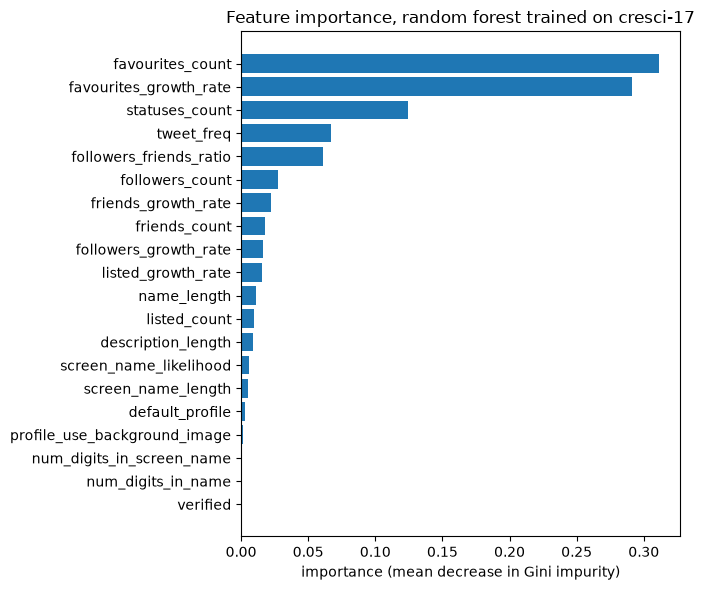

In [16]:
cv_auc_20 = avg_auc  # 20-feature CV AUC, saved for the summary plot at the end

# which features does the model rely on? fit once on all of cresci-17
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(X, y)
importances = pd.Series(clf.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(importances.index, importances.values)
ax.set_xlabel("importance (mean decrease in Gini impurity)")
ax.set_title("Feature importance, random forest trained on cresci-17")
plt.tight_layout()
plt.show()

The plot above shows which of the 20 features the Random Forrest relied on most to tell between bots vs. humans. The mean decrease in Gini impurity is how much a feature’s splits made the trees’ groups purer, averaged over all trees: a measure of how much the model relied on that feature.

### Addtional: LOGO (leave-one-group-out) evaluation

> Can the model recognize a new kind of bot?

Each round removes an entire bot group from training. The model is tested on a bot type it has never seen a single example of.

For each of the 8 bot groups, we train on the other 7 groups plus 80% of the humans, then tested on the excluded group plus the remaining 20% of humans.

In [17]:
# split genuine accounts into two parts: training (80% of genuine accounts) and test (20% of genuine accounts)
genuine = combined[combined['from_dataset'] == 'genuine'].index
X_genuine = X.loc[genuine]
y_genuine = y.loc[genuine]
X_human_train, X_human_test, y_human_train, y_human_test = train_test_split(X_genuine, y_genuine, test_size=0.20, random_state=42)

auc_groups = []

# get the list of bot groups
bot_types = combined[combined['from_dataset'] != 'genuine']['from_dataset'].unique()
for bot in bot_types:
    print(f'{bot} left out')
    left_out = combined[combined["from_dataset"] == bot].index
    kept = combined[(combined["from_dataset"] != bot) & (combined["from_dataset"] != "genuine")].index
    X_train = pd.concat([X_human_train, X.loc[kept]]) 
    y_train = pd.concat([y_human_train, y.loc[kept]])
    X_test = pd.concat([X_human_test, X.loc[left_out]])
    y_test = pd.concat([y_human_test, y.loc[left_out]])

    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf.fit(X_train, y_train)

    prob = clf.predict_proba(X_test)
    auc = roc_auc_score(y_test, prob[:, 1])
    print(f'AUC Score: {auc}')
    group = {'group_name_leftout': bot, 'size': len(left_out), 'auc_score': auc}
    auc_groups.append(group)

print(auc_groups)

fake_followers left out
AUC Score: 0.9890604973496584
spam_bot_1 left out
AUC Score: 0.9897443901589122
spam_bot_2 left out
AUC Score: 0.99431848215382
spam_bot_3 left out
AUC Score: 0.9891140535847185
trad_spam_bot_1 left out
AUC Score: 0.9967589928057554
trad_spam_bot_2 left out
AUC Score: 0.9982446043165468
trad_spam_bot_3 left out
AUC Score: 0.9688808754485245
trad_spam_bot_4 left out
AUC Score: 0.9884987754477269
[{'group_name_leftout': 'fake_followers', 'size': 3351, 'auc_score': 0.9890604973496584}, {'group_name_leftout': 'spam_bot_1', 'size': 991, 'auc_score': 0.9897443901589122}, {'group_name_leftout': 'spam_bot_2', 'size': 3457, 'auc_score': 0.99431848215382}, {'group_name_leftout': 'spam_bot_3', 'size': 464, 'auc_score': 0.9891140535847185}, {'group_name_leftout': 'trad_spam_bot_1', 'size': 1000, 'auc_score': 0.9967589928057554}, {'group_name_leftout': 'trad_spam_bot_2', 'size': 100, 'auc_score': 0.9982446043165468}, {'group_name_leftout': 'trad_spam_bot_3', 'size': 403, 'au

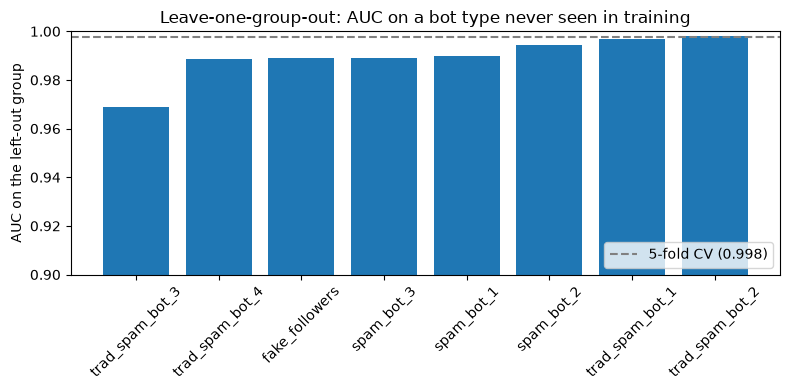

,group_name_leftout,size,auc_score
6,trad_spam_bot_3,403,0.968881
7,trad_spam_bot_4,1128,0.988499
0,fake_followers,3351,0.989060
3,spam_bot_3,464,0.989114
1,spam_bot_1,991,0.989744
2,spam_bot_2,3457,0.994318
4,trad_spam_bot_1,1000,0.996759
5,trad_spam_bot_2,100,0.998245


In [18]:
logo = pd.DataFrame(auc_groups).sort_values("auc_score")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(logo["group_name_leftout"], logo["auc_score"])
ax.axhline(cv_auc_20, linestyle="--", color="gray", label=f"5-fold CV ({cv_auc_20:.3f})")
ax.set_ylim(0.9, 1.0)
ax.set_ylabel("AUC on the left-out group")
ax.set_title("Leave-one-group-out: AUC on a bot type never seen in training")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

logo

Within cresci-17, the model generalizes well to unseen bot subtypes (AUC 0.969–0.998). However, all test humans come from the same source as training humans, so this test does not measure generalization to new populations, which we test next with TwiBot-22.

## Test on TwiBot-22

> A model trained on cresci-17 (bots and humans from 2014–2015) has to classify TwiBot-22 accounts, collected years later by a different team. Both the bots and the humans are new. 

In [19]:
# read in data
data = defaultdict(list) # cols -> rows
with open("data/twibot-22/user.json", "rb") as file:
    for user in ijson.items(file, "item"):
        metrics = user.get("public_metrics") or {}
        
        data["id"].append(user.get("id"))

        data["statuses_count"].append(metrics.get("tweet_count"))
        data["followers_count"].append(metrics.get("followers_count"))
        data["friends_count"].append(metrics.get("following_count"))
        data["listed_count"].append(metrics.get("listed_count"))

        data["screen_name"].append(user.get("username"))
        data["name"].append(user.get("name"))
        data["description"].append(user.get("description"))
        data["verified"].append(user.get("verified"))
        data["created_at"].append(user.get("created_at"))

# create table
twibot_df = pd.DataFrame(data)
twibot_df.loc[[0, 1]]

,id,statuses_count,followers_count,friends_count,listed_count,screen_name,name,description,verified,created_at
0,u1217628182611927040,3098,7316,215,69,boazbaraktcs,Boaz Barak,Theoretical Computer Scientist. See also https...,False,2020-01-16 02:02:55+00:00
1,u2664730894,1823,123,1090,0,wale_io,olawale 💨,creative _,False,2014-07-02 17:56:46+00:00


In [20]:
# convert time
twibot_df["created_at"] = twibot_df["created_at"].apply(convert_date)
twibot_df.loc[[0, 1]]

,id,statuses_count,followers_count,friends_count,listed_count,screen_name,name,description,verified,created_at
0,u1217628182611927040,3098,7316,215,69,boazbaraktcs,Boaz Barak,Theoretical Computer Scientist. See also https...,False,2020-01-16 02:02:55+00:00
1,u2664730894,1823,123,1090,0,wale_io,olawale 💨,creative _,False,2014-07-02 17:56:46+00:00


In [21]:
print(twibot_df["created_at"].dtype)
print(twibot_df["created_at"].isna().sum())
print(twibot_df["created_at"].max())

datetime64[us, UTC]
0
2022-03-14 02:42:20+00:00


TwiBot-22 lacks a collection timestamp, so the most recent account creation time in the dataset (2022-03-14 02:42 UTC) was used as the probe time for all accounts

In [22]:
most_recent = twibot_df["created_at"].max()

# twibot-22 has no favourites_count, default_profile, profile_use_background_image,
# so build_features skips those , total 16 features
X_twibot = build_features(twibot_df, probe=most_recent)

# same 16 columns, same order, for the cross-dataset test
shared = X_twibot.columns
X_cresci_16 = X[shared] # only the 16 features from X above

print(X.shape, X_twibot.shape, X_cresci_16.shape)  # expect 20, 16, 16 columns
print(list(X_cresci_16.columns) == list(X_twibot.columns))  # expect True


(14368, 20) (1000000, 16) (14368, 16)
True


In [23]:
# get the labels and splits used
label_df = pd.read_csv('data/twibot-22/label.csv')
split_df = pd.read_csv('data/twibot-22/split.csv')

twibot_labeled = pd.merge(twibot_df, label_df, on="id")
twibot_full = pd.merge(twibot_labeled, split_df, on="id")

# create same column for "is_bot" as with cresci-17
twibot_full["is_bot"] = (twibot_full["label"] != "human").astype(int)
twibot_full = twibot_full.drop(["label"], axis=1)

# set aside test split
twibot_test = twibot_full[twibot_full["split"] == "test"]

# build features
X_twibot = build_features(twibot_test, probe=most_recent)
y_twibot = twibot_test["is_bot"]

In [24]:
clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(X_cresci_16, y) # same y as for X, train on cresci-17 to compare with the 16 features only
prob = clf.predict_proba(X_twibot)
auc = roc_auc_score(y_twibot, prob[:, 1])

print(f'AUC for cresci-17 with ONLY the common 16 features: {auc}')

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []

# baseline 5 fold cv with the same X above but only the 16 features
for i, (train_index, test_index) in enumerate(skf.split(X_cresci_16, y)):
    print(f"Fold {i}:")
    X_train = X_cresci_16.iloc[train_index]
    y_train = y.iloc[train_index]
    clf.fit(X_train, y_train)
    X_test = X_cresci_16.iloc[test_index]
    y_test = y.iloc[test_index]
    prob = clf.predict_proba(X_test) # returns prob of [0, 1]
    auc = roc_auc_score(y_test, prob[:, 1]) # takes in y_true, y_score
    print(f'AUC Score for cresci-17 with ONLY the common 16 feautures: {auc}')
    auc_scores.append(auc)

avg_auc = sum(auc_scores) / len(auc_scores)
print(f'Avegerage AUC Score for cresci-17 with ONLY the common 16 features: {avg_auc}')

AUC for cresci-17 with ONLY the common 16 features: 0.6058314455518213
Fold 0:
AUC Score for cresci-17 with ONLY the common 16 feautures: 0.9931065335890994
Fold 1:
AUC Score for cresci-17 with ONLY the common 16 feautures: 0.9950670395303767
Fold 2:
AUC Score for cresci-17 with ONLY the common 16 feautures: 0.9936311620735537
Fold 3:
AUC Score for cresci-17 with ONLY the common 16 feautures: 0.9948246361588415
Fold 4:
AUC Score for cresci-17 with ONLY the common 16 feautures: 0.9953112167096717
Avegerage AUC Score for cresci-17 with ONLY the common 16 features: 0.9943881176123085


| Test | Features | AUC |
|---|---|---|
| cresci-17 cross-validation | 20 | 0.998 |
| cresci-17 cross-validation | 16 | 0.994 |
| cresci-17 → TwiBot-22 | 16 | **0.606** |

Dropping the 4 features TwiBot-22 lacks barely changes the cross-validation score (0.998 → 0.994), so they are not the
reason for the drop. Moving to a new dataset is: a model that looks nearly perfect on cresci-17 is only slightly better
than a coin flip (0.5) on TwiBot-22. 

> This reproduces the paper's central finding that high cross-validation accuracy
says little about performance on new data.

### TwiBot-22 valid split

For data selection we also need TwiBot-22's **valid** split. It is used only to *choose* the training data,
so the test split above stays untouched until the final comparison.

In [25]:
twibot_valid = twibot_full[twibot_full["split"] == "val"]
X_twibot_valid = build_features(twibot_valid, probe=most_recent)
y_twibot_valid = twibot_valid["is_bot"]

print("test:", X_twibot.shape, y_twibot.value_counts().to_dict())
print("valid:", X_twibot_valid.shape, y_twibot_valid.value_counts().to_dict())
print(list(X_twibot_valid.columns) == list(X_cresci_16.columns))  # expect True

test: (100000, 16) {0: 70556, 1: 29444}
valid: (200000, 16) {0: 144087, 1: 55913}
True


## Data Selection

> Can we generalize better by choosing which data to train on, instead of using all of it?

Yang et al. found that training on a well chosen subset of datasets generalizes better than throwing everything into the classifier (more training data $\ne$ better). The same idea was aplied to cresci-17's groups: every candidate model trains on the genuine accounts plus one combination of the 8 bot groups. With 8 groups there are 2⁸ − 1 = **255** combinations.

Each candidate gets two scores:

1. **cresci-17 cross-validation AUC**: 5-fold CV on its own training data
2. **TwiBot-22 valid AUC**: trained on all of its data, tested on TwiBot-22's *valid* split

Like the paper, the candidates are ranked on each test and the one with the **smallest product of ranks** is chosen. (The paper also used holdout datasets and correlation with Botometer, which we don't have.)

We select using the **valid** split only. Only the winner is then evaluated on the **test** split, once. Picking the best of 255 models by their test score and then reporting that score would make the result look better than it really is.

This runs 255 × 6 = 1,530 random forests and takes a while...

So we try every combination of bot groups, keep the one that does well on both familiar data and new data, and test only that winner on data we never used, so the final score is realistic.

In [26]:
bot_groups = sorted(g for g in combined["from_dataset"].unique() if g != "genuine")

# every non-empty subset of the 8 bot groups -> 255 combinations
combos = [c for r in range(1, len(bot_groups) + 1) for c in combinations(bot_groups, r)]
print(len(bot_groups), "bot groups ->", len(combos), "combinations")

# genuine accounts + the given bot groups (16 shared features)
def train_data(groups):
    mask = combined["from_dataset"].isin(["genuine"] + list(groups))
    return X_cresci_16[mask], y[mask]

# 5-fold cross-validation AUC on the candidate's own training data
def cv_auc(X_c, y_c): 
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []
    for train_index, test_index in skf.split(X_c, y_c):
        clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
        clf.fit(X_c.iloc[train_index], y_c.iloc[train_index])
        prob = clf.predict_proba(X_c.iloc[test_index])
        scores.append(roc_auc_score(y_c.iloc[test_index], prob[:, 1]))
    return np.mean(scores)

# train on all of the candidate's data, test on another dataset
def holdout_auc(X_c, y_c, X_eval, y_eval):
    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf.fit(X_c, y_c)
    return roc_auc_score(y_eval, clf.predict_proba(X_eval)[:, 1])

8 bot groups -> 255 combinations


In [27]:
# takes while so once computed its saved and can be read in to avoid recomputing
results_path = Path("results/data_selection.csv")

if results_path.exists():
    selection = pd.read_csv(results_path)
    print(f"loaded {len(selection)} results from {results_path}")
else:
    rows = []
    for i, groups in enumerate(combos, start=1):
        X_c, y_c = train_data(groups)
        cv_auc_score = cv_auc(X_c, y_c) # 5-fold cv
        val_auc = holdout_auc(X_c, y_c, X_twibot_valid, y_twibot_valid) # train on candidates data, test on another
        rows.append({
            "groups": " + ".join(groups),
            "n_groups": len(groups),
            "n_bots": int(y_c.sum()),
            "cv_auc": cv_auc_score,
            "val_auc": val_auc,
        })
        if i % 25 == 0 or i == len(combos):
            print(f"{i}/{len(combos)} done")
    selection = pd.DataFrame(rows)
    results_path.parent.mkdir(exist_ok=True)
    selection.to_csv(results_path, index=False)

# rank on each test (1 = best), then pick the smallest product of ranks
selection["cv_rank"] = selection["cv_auc"].rank(ascending=False)
selection["val_rank"] = selection["val_auc"].rank(ascending=False)
selection["rank_product"] = selection["cv_rank"] * selection["val_rank"]
selection = selection.sort_values("rank_product").reset_index(drop=True)

selection.head(10)

loaded 255 results from results/data_selection.csv


,groups,n_groups,n_bots,cv_auc,val_auc,cv_rank,val_rank,rank_product
0,fake_followers + spam_bot_2 + trad_spam_bot_3,3,7211,0.997439,0.593403,37.0,1.0,37.0
1,fake_followers + trad_spam_bot_2 + trad_spam_b...,3,3854,0.997328,0.593235,44.0,2.0,88.0
2,fake_followers + spam_bot_2 + trad_spam_bot_2 ...,4,7311,0.997256,0.592431,47.0,3.0,141.0
3,spam_bot_2 + trad_spam_bot_3,2,3860,0.997394,0.591894,40.0,4.0,160.0
4,fake_followers + trad_spam_bot_2 + trad_spam_b...,3,4579,0.998941,0.564678,3.0,56.0,168.0
5,fake_followers,1,3351,0.998304,0.574121,9.0,24.0,216.0
6,spam_bot_2 + trad_spam_bot_2 + trad_spam_bot_3,3,3960,0.997260,0.591370,46.0,5.0,230.0
7,trad_spam_bot_4,1,1128,0.999988,0.509205,1.0,232.0,232.0
8,fake_followers + spam_bot_2 + trad_spam_bot_2 ...,5,8439,0.997535,0.579432,33.0,8.0,264.0
9,fake_followers + spam_bot_2 + trad_spam_bot_3 ...,4,8339,0.997605,0.578335,28.0,10.0,280.0


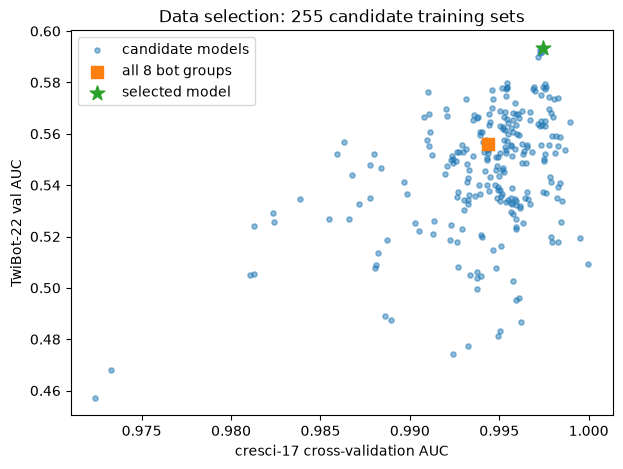

selected: fake_followers + spam_bot_2 + trad_spam_bot_3


In [28]:
all_groups = " + ".join(bot_groups)
best = selection.iloc[0]
everything = selection[selection["groups"] == all_groups].iloc[0]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(selection["cv_auc"], selection["val_auc"], s=14, alpha=0.5, label="candidate models")
ax.scatter(everything["cv_auc"], everything["val_auc"], s=80, marker="s", label="all 8 bot groups")
ax.scatter(best["cv_auc"], best["val_auc"], s=120, marker="*", label="selected model")
ax.set_xlabel("cresci-17 cross-validation AUC")
ax.set_ylabel("TwiBot-22 val AUC")
ax.set_title("Data selection: 255 candidate training sets")
ax.legend()
plt.show()

print("selected:", best["groups"])

The x-axis represents the AUC score of each group on familiar data (cresci-17). The y-axis represents the AUC score of each group on new data (twibot-22).

### Final test

The selected model and the "all data" baseline are each evaluated **once** on TwiBot-22's **test** split.

In [29]:
final = []
for label, groups in [("all 8 bot groups (baseline)", bot_groups),
                      ("selected", best["groups"].split(" + "))]:
    X_c, y_c = train_data(groups)
    final.append({
        "model": label,
        "training groups": " + ".join(groups),
        "cresci-17 CV AUC": cv_auc(X_c, y_c),
        "TwiBot-22 test AUC": holdout_auc(X_c, y_c, X_twibot, y_twibot),
    })

pd.DataFrame(final)

,model,training groups,cresci-17 CV AUC,TwiBot-22 test AUC
0,all 8 bot groups (baseline),fake_followers + spam_bot_1 + spam_bot_2 + spa...,0.994388,0.605831
1,selected,fake_followers + spam_bot_2 + trad_spam_bot_3,0.997439,0.649033


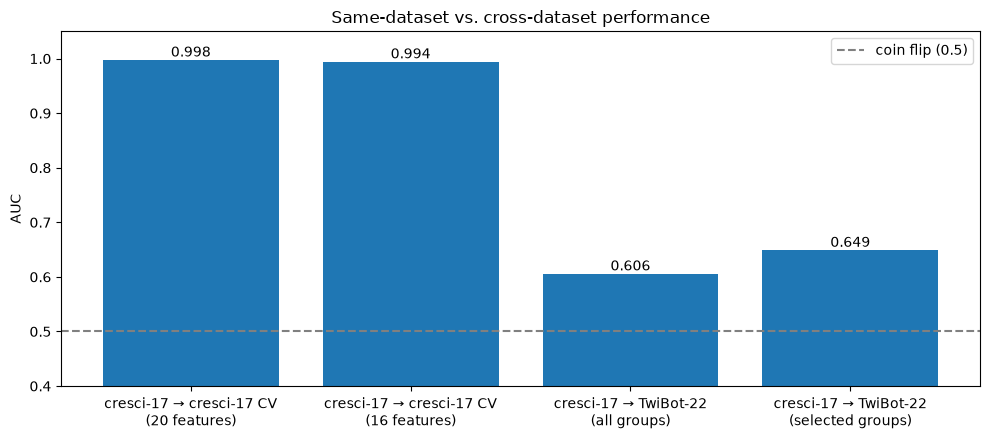

In [30]:
summary = pd.Series({
    "cresci-17 → cresci-17 CV\n(20 features)": cv_auc_20,
    "cresci-17 → cresci-17 CV\n(16 features)": final[0]["cresci-17 CV AUC"],
    "cresci-17 → TwiBot-22\n(all groups)": final[0]["TwiBot-22 test AUC"],
    "cresci-17 → TwiBot-22\n(selected groups)": final[1]["TwiBot-22 test AUC"],
})

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(summary.index, summary.values)
ax.bar_label(bars, fmt="%.3f")
ax.axhline(0.5, linestyle="--", color="gray", label="coin flip (0.5)")
ax.set_ylim(0.4, 1.05)
ax.set_ylabel("AUC")
ax.set_title("Same-dataset vs. cross-dataset performance")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

The chart above shows that the model is nearly perfect on cresci-17 (0.998) but drops to 0.606 on TwiBot-22; training on a selected combination of bot groups raises this to 0.649. This is consistent with the paper's main argument: the right combination of training data generalizes better than using all of it.

### Precision, recall and F1

AUC measures how well the model *ranks* accounts, but using a detector means picking a cutoff: accounts with a bot
score above the threshold are called bots. Like the paper (Fig. 4), we report precision, recall and F1:

- **Precision**: of the accounts we flagged as bots, how many really are bots
- **Recall**: of the real bots, how many we caught
- **F1**: a single score that balances the two (their harmonic mean)

We report them at the default threshold of 0.5 and at the threshold that maximizes F1, for the selected model on
cresci-17 (cross-validation) and for both models on TwiBot-22's test split.

In [31]:
# AUC, precision/recall/F1 at 0.5, and the threshold that maximizes F1
def threshold_metrics(name, y_true, p_bot):
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, p_bot >= 0.5, average="binary", zero_division=0)
    P, R, T = precision_recall_curve(y_true, p_bot)
    F = 2 * P[:-1] * R[:-1] / np.maximum(P[:-1] + R[:-1], 1e-12)
    k = np.argmax(F)
    return {"model / test": name, "AUC": roc_auc_score(y_true, p_bot),
            "precision@0.5": prec, "recall@0.5": rec, "F1@0.5": f1,
            "best threshold": T[k], "best F1": F[k], "precision@best": P[k], "recall@best": R[k]}

def fit_predict(groups, X_eval):
    X_c, y_c = train_data(groups)
    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    clf.fit(X_c, y_c)
    return clf.predict_proba(X_eval)[:, 1]

selected_groups = best["groups"].split(" + ")

# cross-validation on cresci-17: out-of-fold bot scores, so every account is scored by a model that didn't train on it
X_sel, y_sel = train_data(selected_groups)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p_cv = cross_val_predict(RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
                         X_sel, y_sel, cv=skf, method="predict_proba")[:, 1]

# cross-dataset: TwiBot-22 test split
p_twibot_all = fit_predict(bot_groups, X_twibot)
p_twibot_sel = fit_predict(selected_groups, X_twibot)

metrics = pd.DataFrame([
    threshold_metrics("selected, cresci-17 CV", y_sel, p_cv),
    threshold_metrics("all groups, TwiBot-22 test", y_twibot, p_twibot_all),
    threshold_metrics("selected, TwiBot-22 test", y_twibot, p_twibot_sel),
]).set_index("model / test").round(3)
metrics

,AUC,precision@0.5,recall@0.5,F1@0.5,best threshold,best F1,precision@best,recall@best
model / test,,,,,,,,
"selected, cresci-17 CV",0.997,0.993,0.986,0.989,0.50,0.989,0.993,0.986
"all groups, TwiBot-22 test",0.606,0.368,0.535,0.436,0.23,0.472,0.334,0.805
"selected, TwiBot-22 test",0.649,0.475,0.364,0.412,0.12,0.485,0.364,0.728


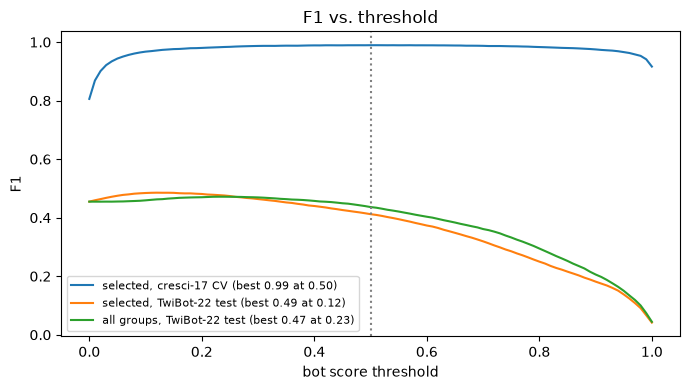

In [32]:
# F1 vs. threshold, like the paper's Fig. 4b
fig, ax = plt.subplots(figsize=(7, 4))
for label, y_true, p_bot in [("selected, cresci-17 CV", y_sel, p_cv),
                             ("selected, TwiBot-22 test", y_twibot, p_twibot_sel),
                             ("all groups, TwiBot-22 test", y_twibot, p_twibot_all)]:
    P, R, T = precision_recall_curve(y_true, p_bot)
    F = 2 * P[:-1] * R[:-1] / np.maximum(P[:-1] + R[:-1], 1e-12)
    ax.plot(T, F, label=f"{label} (best {F.max():.2f} at {T[np.argmax(F)]:.2f})")
ax.axvline(0.5, linestyle=":", color="gray")
ax.set_xlabel("bot score threshold")
ax.set_ylabel("F1")
ax.set_title("F1 vs. threshold")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

On cresci-17, F1 stays near 0.99 across thresholds; on TwiBot-22 it peaks below 0.5 and only at much lower thresholds (0.12–0.23), so both the model’s accuracy and its best cutoff fail to carry over to new data.

## Comparison with Yang et al. (2020)

- **Same pattern as the paper.** In both studies, a selected subset of training data beats training on everything, in cross-validation (paper 0.95 → 0.98, ours 0.994 → 0.997) and on unseen data (ours 0.606 → 0.649 on TwiBot-22).
- **Our gain matches the paper's gains on its hardest holdout datasets.** The paper's selected model improved by +0.04 on gilani-17 and +0.03 on cresci-rtbust, with absolute AUCs of 0.60–0.68. Our +0.04 on TwiBot-22, at 0.61–0.65, falls in the same range.
- **We don't reproduce the large gains.** The paper's biggest improvements (midterm-18: 0.83 → 0.99) came from choosing among 8 diverse datasets. All of our candidate training sets come from a single 2014–2015 dataset with the same human accounts, so selection has much less to choose from.
- **Thresholds and F1.** The paper's best threshold dropped from 0.48 (cross-validation) to 0.32 (cross-domain), and its F1 from 0.94 to 0.77. We see the same pattern, but stronger: our best threshold drops from 0.50 on cresci-17 to 0.12–0.23 on TwiBot-22, and F1 from 0.989 to 0.485. A cutoff tuned on the training data does not carry over: on TwiBot-22 the model gives bots lower scores, so it only catches them with a much lower threshold. As in the paper, data selection mainly improved precision at the default 0.5 threshold (0.368 → 0.475, so fewer humans wrongly flagged), at the cost of recall (0.535 → 0.364).

## Alternative Model: Logistic Regression

> Is the drop on TwiBot-22 caused by the **data**, or by the random forest **overfitting** to cresci-17?

We rerun the same experiments with a very different model. A random forest combines hundreds of if/then trees and can learn very specific patterns. Logistic regression gives each feature one weight, adds them up, and turns the total into a probability: a single straight boundary between bots and humans.

- **If logistic regression also drops** on TwiBot-22, the problem is the data, not the model.
- **If it drops less**, the random forest is likely overfitting to quirks of cresci-17.

**How it trains:** by minimizing **log loss** (binary cross-entropy), which heavily punishes confident wrong
predictions, with L2 regularization (scikit-learn's default) to keep the weights from growing too large.

**Preprocessing:** unlike a random forest, logistic regression is sensitive to scale. Counts range from 0 to millions, so we first apply `log(1 + x)` (as the paper does before its PCA analysis) and then standardize every feature. Both steps sit inside a `Pipeline`, so they are fit on the training data only and nothing leaks from the test data.

We grade it exactly like the random forest: AUC first, then precision, recall and F1.

In [33]:
# factory functions
def make_rf():
    return RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)


def make_lr():
    return make_pipeline(
        FunctionTransformer(np.log1p), # log(1 + x): tames huge counts (all features are >= 0)
        StandardScaler(), # every feature -> mean 0, standard deviation 1
        LogisticRegression(max_iter=1000), # log loss + L2 regularization
    )


def cv_scores(make_model, X_c, y_c):
    """5-fold cross-validation AUCs for any model"""
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = []
    for train_index, test_index in skf.split(X_c, y_c):
        model = make_model()
        model.fit(X_c.iloc[train_index], y_c.iloc[train_index])
        prob = model.predict_proba(X_c.iloc[test_index])
        scores.append(roc_auc_score(y_c.iloc[test_index], prob[:, 1]))
    return np.array(scores)


def train_and_score(make_model, X_c, y_c, X_eval):
    """train on (X_c, y_c), return P(bot) for every account in X_eval"""
    model = make_model()
    model.fit(X_c, y_c)
    return model.predict_proba(X_eval)[:, 1]

### Same experiments as the random forest

1. 5-fold cross-validation on cresci-17, with all 20 features and with the 16 shared ones
2. Train on all of cresci-17 (16 features), test on TwiBot-22's test split

In [34]:
lr_cv_20 = cv_scores(make_lr, X, y)
lr_cv_16 = cv_scores(make_lr, X_cresci_16, y)

p_lr_all = train_and_score(make_lr, X_cresci_16, y, X_twibot)
lr_twibot_all = roc_auc_score(y_twibot, p_lr_all)

print(f"cresci-17 5-fold CV AUC, 20 features: {lr_cv_20.mean():.3f} ± {lr_cv_20.std():.3f}")
print(f"cresci-17 5-fold CV AUC, 16 features: {lr_cv_16.mean():.3f} ± {lr_cv_16.std():.3f}")
print(f"cresci-17 -> TwiBot-22 AUC:           {lr_twibot_all:.3f}")

cresci-17 5-fold CV AUC, 20 features: 0.995 ± 0.001
cresci-17 5-fold CV AUC, 16 features: 0.960 ± 0.004
cresci-17 -> TwiBot-22 AUC:           0.639


### Data selection with logistic regression

The same 255 combinations and the same ranking (cross-validation AUC rank × TwiBot-22 val AUC rank). Logistic
regression trains in a fraction of a second, so this takes a minute or two. Results are saved to
`results/data_selection_lr.csv`.

In [35]:
lr_results_path = Path("results/data_selection_lr.csv")

if lr_results_path.exists():
    lr_selection = pd.read_csv(lr_results_path)
    print(f"loaded {len(lr_selection)} results from {lr_results_path}")
else:
    rows = []
    for i, groups in enumerate(combos, start=1):
        X_c, y_c = train_data(groups)
        rows.append({
            "groups": " + ".join(groups),
            "n_groups": len(groups),
            "n_bots": int(y_c.sum()),
            "cv_auc": cv_scores(make_lr, X_c, y_c).mean(),
            "val_auc": roc_auc_score(y_twibot_valid, train_and_score(make_lr, X_c, y_c, X_twibot_valid)),
        })
        if i % 50 == 0 or i == len(combos):
            print(f"{i}/{len(combos)} done")
    lr_selection = pd.DataFrame(rows)
    lr_results_path.parent.mkdir(exist_ok=True)
    lr_selection.to_csv(lr_results_path, index=False)

# rank on each test (1 = best), pick the smallest product of ranks
lr_selection["cv_rank"] = lr_selection["cv_auc"].rank(ascending=False)
lr_selection["val_rank"] = lr_selection["val_auc"].rank(ascending=False)
lr_selection["rank_product"] = lr_selection["cv_rank"] * lr_selection["val_rank"]
lr_selection = lr_selection.sort_values("rank_product").reset_index(drop=True)

lr_best_groups = lr_selection.iloc[0]["groups"].split(" + ")
print("selected:", " + ".join(lr_best_groups))
lr_selection.head(10)

loaded 255 results from results/data_selection_lr.csv
selected: spam_bot_2 + trad_spam_bot_2


,groups,n_groups,n_bots,cv_auc,val_auc,cv_rank,val_rank,rank_product
0,spam_bot_2 + trad_spam_bot_2,2,3557,0.992030,0.664996,21.0,1.0,21.0
1,fake_followers + spam_bot_2 + trad_spam_bot_2,3,6908,0.991802,0.643639,23.0,2.0,46.0
2,fake_followers + spam_bot_2,2,6808,0.994251,0.628494,13.0,6.0,78.0
3,spam_bot_2 + trad_spam_bot_2 + trad_spam_bot_3,3,3960,0.988989,0.639667,38.0,3.0,114.0
4,spam_bot_2,1,3457,0.995901,0.611877,7.0,18.0,126.0
5,fake_followers + spam_bot_2 + trad_spam_bot_2 ...,4,7311,0.989582,0.632168,33.0,4.0,132.0
6,spam_bot_2 + trad_spam_bot_3,2,3860,0.990503,0.629861,29.0,5.0,145.0
7,fake_followers + spam_bot_2 + trad_spam_bot_3,3,7211,0.991361,0.625665,25.0,7.0,175.0
8,trad_spam_bot_4,1,1128,0.999986,0.476674,1.0,234.0,234.0
9,spam_bot_2 + trad_spam_bot_2 + trad_spam_bot_4,3,4685,0.989849,0.619238,31.0,9.0,279.0


### Final test and F1

The selected logistic regression model and the all-groups baseline, each evaluated once on TwiBot-22's test split.

In [36]:
X_c, y_c = train_data(lr_best_groups)
lr_cv_sel = cv_scores(make_lr, X_c, y_c).mean()
p_lr_sel = train_and_score(make_lr, X_c, y_c, X_twibot)

lr_metrics = pd.DataFrame([
    threshold_metrics("LR all groups, TwiBot-22 test", y_twibot, p_lr_all),
    threshold_metrics("LR selected, TwiBot-22 test", y_twibot, p_lr_sel),
]).set_index("model / test").round(3)
lr_metrics

,AUC,precision@0.5,recall@0.5,F1@0.5,best threshold,best F1,precision@best,recall@best
model / test,,,,,,,,
"LR all groups, TwiBot-22 test",0.639,0.350,0.765,0.481,0.586,0.482,0.362,0.721
"LR selected, TwiBot-22 test",0.707,0.527,0.415,0.464,0.022,0.534,0.437,0.686


### Random forest vs. logistic regression

RF selected groups: fake_followers + spam_bot_2 + trad_spam_bot_3
LR selected groups: spam_bot_2 + trad_spam_bot_2


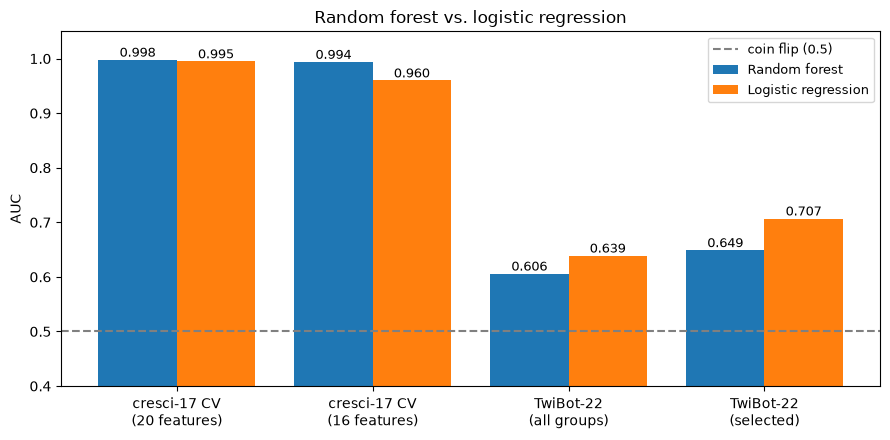

,Random forest,Logistic regression
"cresci-17 CV AUC, 20 features",0.998,0.995
"cresci-17 CV AUC, 16 features",0.994,0.960
"TwiBot-22 test AUC, all groups",0.606,0.639
"TwiBot-22 test AUC, selected",0.649,0.707
"TwiBot-22 best F1, all groups",0.472,0.482
"TwiBot-22 best F1, selected",0.485,0.534


In [37]:
rows = [
    "cresci-17 CV AUC, 20 features",
    "cresci-17 CV AUC, 16 features",
    "TwiBot-22 test AUC, all groups",
    "TwiBot-22 test AUC, selected",
    "TwiBot-22 best F1, all groups",
    "TwiBot-22 best F1, selected",
]
model_comparison = pd.DataFrame({
    "Random forest": [
        cv_auc_20,
        final[0]["cresci-17 CV AUC"],
        final[0]["TwiBot-22 test AUC"],
        final[1]["TwiBot-22 test AUC"],
        metrics.loc["all groups, TwiBot-22 test", "best F1"],
        metrics.loc["selected, TwiBot-22 test", "best F1"],
    ],
    "Logistic regression": [
        lr_cv_20.mean(),
        lr_cv_16.mean(),
        lr_twibot_all,
        lr_metrics.loc["LR selected, TwiBot-22 test", "AUC"],
        lr_metrics.loc["LR all groups, TwiBot-22 test", "best F1"],
        lr_metrics.loc["LR selected, TwiBot-22 test", "best F1"],
    ],
}, index=rows).astype(float).round(3)

print("RF selected groups:", best["groups"])
print("LR selected groups:", " + ".join(lr_best_groups))

# AUC rows side by side
auc_rows = model_comparison.iloc[:4]
x = np.arange(len(auc_rows))
fig, ax = plt.subplots(figsize=(9, 4.5))
b1 = ax.bar(x - 0.2, auc_rows["Random forest"], width=0.4, label="Random forest")
b2 = ax.bar(x + 0.2, auc_rows["Logistic regression"], width=0.4, label="Logistic regression")
ax.bar_label(b1, fmt="%.3f", fontsize=9)
ax.bar_label(b2, fmt="%.3f", fontsize=9)
ax.axhline(0.5, linestyle="--", color="gray", label="coin flip (0.5)")
ax.set_xticks(x, ["cresci-17 CV\n(20 features)", "cresci-17 CV\n(16 features)",
                  "TwiBot-22\n(all groups)", "TwiBot-22\n(selected)"])
ax.set_ylim(0.4, 1.05)
ax.set_ylabel("AUC")
ax.set_title("Random forest vs. logistic regression")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

model_comparison

### What logistic regression learned

Because the features are standardized, the weights are comparable: a **positive** weight pushes an account toward
"bot", a **negative** one toward "human", and a larger size means a stronger push. Trained on all of cresci-17 with
the 16 shared features.

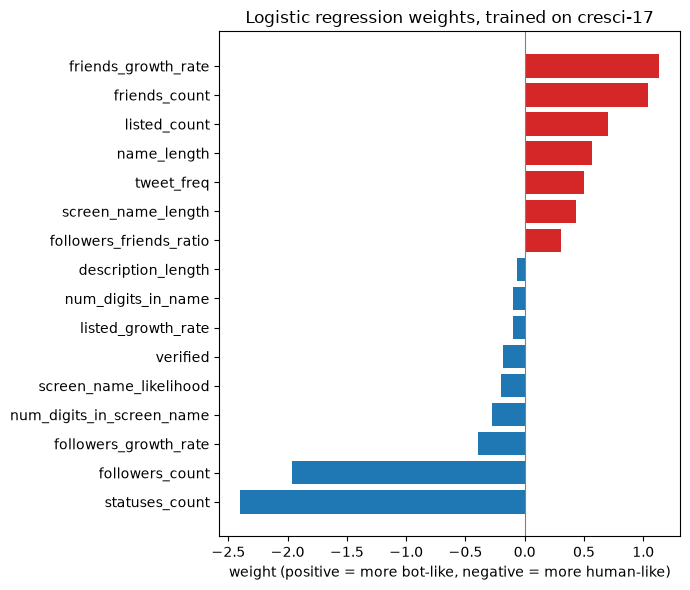

In [38]:
lr_model = make_lr().fit(X_cresci_16, y)
weights = pd.Series(lr_model[-1].coef_[0], index=X_cresci_16.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(weights.index, weights.values, color=["tab:red" if w > 0 else "tab:blue" for w in weights.values])
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("weight (positive = more bot-like, negative = more human-like)")
ax.set_title("Logistic regression weights, trained on cresci-17")
plt.tight_layout()
plt.show()

**Interpretation.** Logistic regression scores slightly lower than the random forest on cresci-17 (CV AUC 0.995 vs. 0.998) but generalizes better to TwiBot-22 (0.639 vs. 0.606 with all groups, 0.707 vs. 0.649 with data selection). Both models still drop on the new dataset, so the main cause of the gap is the data itself: different years, collection methods and types of bots. The smaller drop for the simpler model suggests the random forest also overfits to patterns specific to cresci-17. Data selection helped both models, and helped logistic regression more (+0.068 AUC). As in the paper, a higher cross-validation score did not mean better performance on unseen data: training on traditional spambots 4 alone gave 0.99999 CV AUC but 0.477 on TwiBot-22.